2026-11-24 18:39:19.021936 [W:onnxruntime:, coreml_execution_provider.cc:112 GetCapability] CoreMLExecutionProvider::GetCapability, number of partitions supported by CoreML: 3 number of nodes in the graph: 233 number of nodes supported by CoreML: 230


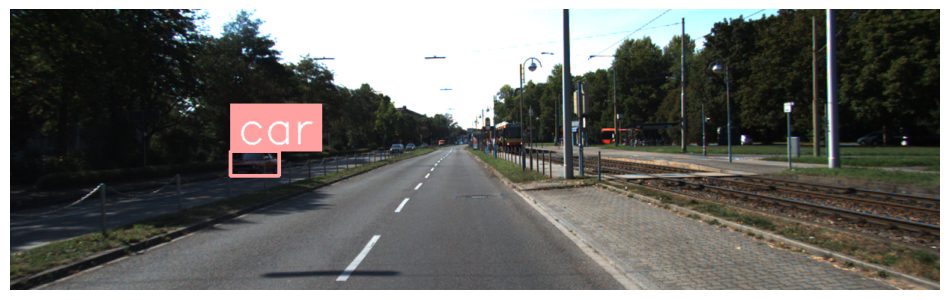

In [3]:
from inference import get_model
import supervision as sv
from inference.core.utils.image_utils import load_image_bgr
image = load_image_bgr("data/raw/testing/image_2/um_000001.png")
model = get_model(model_id="yolov8n-640")
results = model.infer(image)[0]
results = sv.Detections.from_inference(results)
annotator = sv.BoxAnnotator(thickness=4)
annotated_image = annotator.annotate(image, results)
annotator = sv.LabelAnnotator(text_scale=2, text_thickness=2)
annotated_image = annotator.annotate(annotated_image, results)
sv.plot_image(annotated_image)